# A1 · Caderno da Transformada Z

**Ian Esteves Amaral Francisco · Processamento de Sinais · AP2**

Usei Python, NumPy e Matplotlib para verificar as somas e desenhar o plano Z.
A convenção do círculo tracejado, dos polos marcados com × e dos zeros
marcados com ○ vem da função `plot_z_plane` do código da aula.
As três sequências são modelos escolhidos para o trabalho. As motivações
abaixo explicam o formato de cada modelo.

A definição bilateral é $X(z)=\sum_{n=-\infty}^{\infty}x[n]z^{-n}$.
Como todas as sequências são causais, as somas começam em $n=0$.
Escrevo $q=z^{-1}$ para mostrar os atrasos e uso $u[n]$ para o degrau unitário.

## 1. Pulso com subida e decaimento

**Motivação.** Modelo para a leitura de um sensor após um pulso breve.
O sinal começa em zero, sobe nas primeiras amostras e volta a zero.
Escolhi duas constantes de decaimento para modelar esses trechos.

$x_1[n]=[(3/4)^n-(1/4)^n]u[n]$.

**Definição e ROC.** As duas somas geométricas são
$\sum_{n\geq0}(3q/4)^n$ e $\sum_{n\geq0}(q/4)^n$. A interseção de
$|z|>3/4$ com $|z|>1/4$ dá **$|z|>3/4$**. Logo,

$$X_1(z)=\frac{1}{1-3q/4}-\frac{1}{1-q/4}
=\frac{z/2}{(z-3/4)(z-1/4)}.$$

**Inversa por frações parciais.** Em $q$, a forma reduzida é
$(q/2)/[(1-3q/4)(1-q/4)]$. Igualando o numerador a
$A(1-q/4)+B(1-3q/4)$, resulta $A=1$, $B=-1$.
A ROC externa escolhe as duas exponenciais causais.

**Inversa por série de potências.** Expando o produto das duas séries
geométricas e multiplico por $q/2$. Para $n\geq 1$, o coeficiente de $q^n$ é
$\frac12\sum_{k=0}^{n-1}(3/4)^k(1/4)^{n-1-k}=(3/4)^n-(1/4)^n$.
Em $n=0$ o coeficiente é zero. As primeiras amostras são
$0,\ 1/2,\ 1/2,\ 13/32$, iguais às da primeira inversa.

**Estabilidade BIBO.** Se $x_1$ for a resposta ao impulso, os polos
$3/4$ e $1/4$ ficam dentro do círculo. O zero fica em $0$.
A ROC inclui $|z|=1$ e a soma de módulos de $x_1$ é finita. O sistema é estável.

## 2. Oscilação alternada que se apaga

**Motivação.** Modelo de vibração após um impacto, com mudança de sinal
a cada amostra e um componente positivo que desaparece mais rápido.

$x_2[n]=[(-3/5)^n+(1/5)^n]u[n]$.

**Definição e ROC.** As séries são $\sum_{n\geq0}(-3q/5)^n$ e
$\sum_{n\geq0}(q/5)^n$. A interseção dá **$|z|>3/5$**.

$$X_2(z)=\frac{1}{1+3q/5}+\frac{1}{1-q/5}
=\frac{z(2z+2/5)}{(z+3/5)(z-1/5)}.$$

**Inversa por frações parciais.** Igualo o numerador em $q$, $2+2q/5$,
a $A(1-q/5)+B(1+3q/5)$. Daí $A=B=1$.
As duas parcelas têm suporte causal pela ROC.

**Inversa por série de potências.** O produto das duas séries tem
coeficientes $s_n=[(1/5)^{n+1}-(-3/5)^{n+1}]/(4/5)$ para $n\geq0$.
Multiplicando o produto pelo numerador, o coeficiente vira
$2s_n+\tfrac25s_{n-1}=(-3/5)^n+(1/5)^n$, com $s_{-1}=0$.
As duas inversas dão $2,\ -2/5,\ 2/5,\ -26/125$.

**Estabilidade BIBO.** Polos em $-3/5$ e $1/5$. Zeros em $0$ e $-1/5$.
A ROC contém $|z|=1$, e a soma dos módulos é limitada pela soma de duas
geométricas decrescentes. O sistema causal é estável.

## 3. Realimentação que cresce

**Motivação.** Modelo de teste de um controlador mal ajustado.
Duas etapas recursivas iguais com ganho $1{,}1$ acumulam a resposta.
É o caso de contraste para o desenho do círculo unitário.

$x_3[n]=(n+1)(11/10)^n u[n]$.

**Definição e ROC.** Com $r=11q/10$, a soma é $\sum_{n\geq0}(n+1)r^n$.
O produto de duas geométricas dá $n+1$ parcelas para cada potência $r^n$.

$$X_3(z)=\frac{1}{(1-11q/10)^2}=\frac{z^2}{(z-11/10)^2},\qquad |z|>11/10.$$

A ROC vem de $|r|<1$. Na fronteira os termos da soma não tendem a zero.

**Inversa por frações parciais.** Para o polo repetido, escrevo
$A/(1-r)+B/(1-r)^2$. De $A(1-r)+B=1$, obtenho $A=0$ e $B=1$.
A parcela de polo duplo é a convolução causal de duas sequências
$(11/10)^n u[n]$. A soma de convolução tem $n+1$ parcelas iguais.

**Inversa por série de potências.** Derivo
$r/(1-r)=\sum_{n\geq0}r^{n+1}$. A derivada é
$1/(1-r)^2=\sum_{n\geq0}(n+1)r^n$. Com $r=11q/10$, o coeficiente
é $(n+1)(11/10)^n$. Os dois métodos dão
$1,\ 2{,}2,\ 3{,}63,\ 5{,}324$.

**Estabilidade BIBO.** Polo duplo em $1{,}1$ e zero duplo em $0$.
O círculo $|z|=1$ fica fora da ROC. A entrada limitada $\delta[n]$ já produz
saída crescente e ilimitada. O sistema causal é instável.

## 4. Verificação de duas propriedades nas três sequências

**Deslocamento.** Para cada $i$, troco $m=n-2$ na definição:

$$\sum_{n=2}^{\infty} x_i[n-2]z^{-n}
=z^{-2}\sum_{m=0}^{\infty}x_i[m]z^{-m}=q^2X_i(z).$$

Logo, os resultados são $q^3/[2(1-3q/4)(1-q/4)]$ para $x_1$,
$q^2(2+2q/5)/[(1+3q/5)(1-q/5)]$ para $x_2$ e
$q^2/(1-11q/10)^2$ para $x_3$. O atraso não muda nenhuma das três ROCs externas.

**Linearidade.** Para cada $i$, uso $y_i[n]=2x_i[n]-x_i[n-2]$.
Distribuindo a soma da definição, $Y_i=2X_i-q^2X_i=(2-q^2)X_i$.
Os polos originais mais externos não são cancelados por $2-q^2$,
de modo que cada ROC permanece igual à de $X_i$.

O código compara a soma truncada a 120 termos com as três expressões
fechadas e com os resultados das duas propriedades em $z=1{,}4+0{,}3j$,
um ponto comum às três ROCs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(120)
z = 1.4 + 0.3j
q = 1 / z
sequencias = [
    .75**n - .25**n,
    (-.6)**n + .2**n,
    (n + 1) * 1.1**n,
]
fechadas = [
    z / (2 * (z - .75) * (z - .25)),
    z * (2*z + .4) / ((z + .6) * (z - .2)),
    z**2 / (z - 1.1)**2,
]
for i, (x, X) in enumerate(zip(sequencias, fechadas), 1):
    atraso = np.r_[0, 0, x[:-2]]
    verificadas = [np.dot(x, q**n), np.dot(atraso, q**n),
                   np.dot(2*x - atraso, q**n)]
    esperadas = [X, q**2 * X, (2 - q**2) * X]
    erro = max(abs(np.array(verificadas) - esperadas))
    assert erro < 1e-9
    print(f'x{i}: erro máximo {erro:.2e}')

x1: erro máximo 4.74e-16
x2: erro máximo 8.95e-16
x3: erro máximo 9.00e-12


## 5. Plano Z

O círculo tracejado é $|z|=1$. A circunferência laranja pontilhada
delimita cada ROC, que se estende para fora dela. O algarismo 2
indica raiz dupla. No terceiro caso, a fronteira da ROC fica além
do círculo unitário.

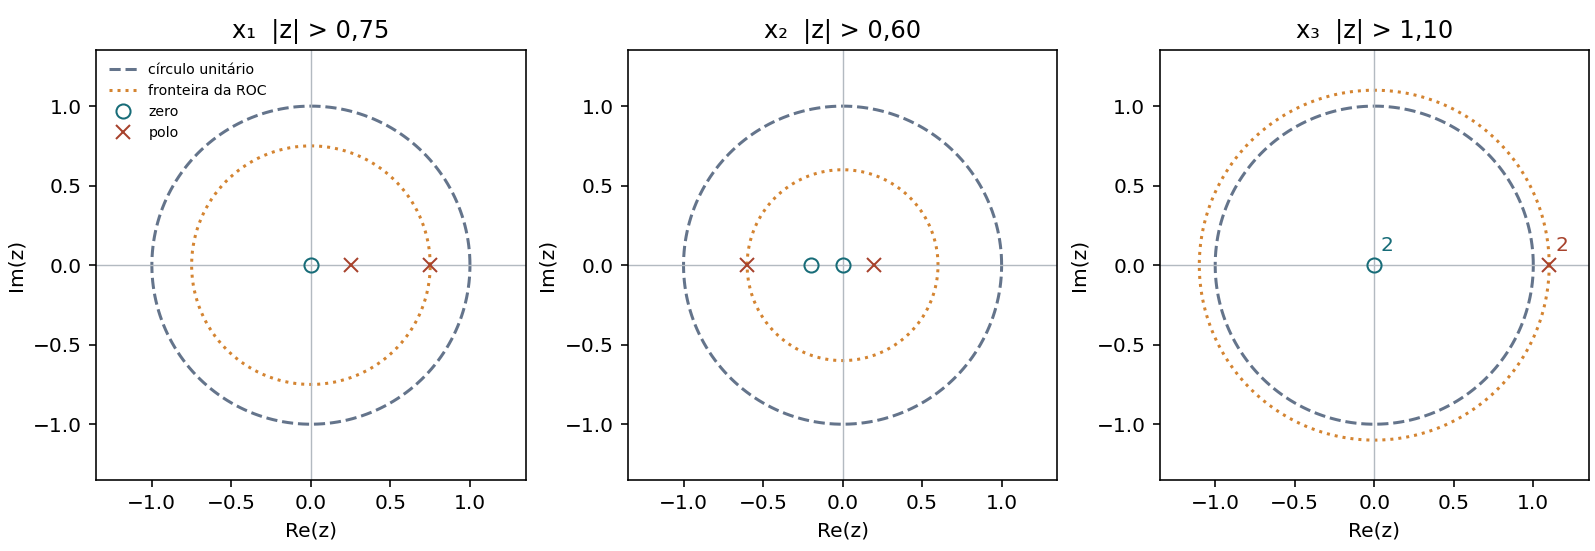

In [2]:
casos = [
    ("x₁  |z| > 0,75", [0.75, 0.25], [0], 0.75),
    ("x₂  |z| > 0,60", [-0.60, 0.20], [0, -0.20], 0.60),
    ("x₃  |z| > 1,10", [1.10, 1.10], [0, 0], 1.10),
]

angulo = np.linspace(0, 2*np.pi, 400)
circulo = np.exp(1j * angulo)
fig, eixos = plt.subplots(1, 3, figsize=(11, 3.8), layout="constrained")
for ax, (titulo, polos, zeros, raio) in zip(eixos, casos):
    ax.plot(circulo.real, circulo.imag, "--", color="#64748b", label="círculo unitário")
    ax.plot(raio*circulo.real, raio*circulo.imag, ":", color="#d48431", label="fronteira da ROC")
    ax.axhline(0, color="#b3bac1", linewidth=.7)
    ax.axvline(0, color="#b3bac1", linewidth=.7)
    for raizes, marca, cor, legenda in [
        (zeros, "o", "#176c78", "zero"), (polos, "x", "#a7422c", "polo")
    ]:
        unicas, contagens = np.unique(np.asarray(raizes, complex), return_counts=True)
        ax.plot(unicas.real, unicas.imag, linestyle="none", marker=marca,
                markersize=7, markerfacecolor="none", color=cor, label=legenda)
        for raiz, qtd in zip(unicas, contagens):
            if qtd > 1:
                ax.annotate(str(qtd), (raiz.real, raiz.imag), xytext=(3, 7),
                            textcoords="offset points", color=cor)
    ax.set(title=titulo, xlabel="Re(z)", ylabel="Im(z)",
           xlim=(-1.35, 1.35), ylim=(-1.35, 1.35))
    ax.set_aspect("equal")
eixos[0].legend(loc="upper left", fontsize=7, frameon=False)
plt.show()

**Material consultado.** *Apostila de Transformada Z*, capítulos 2 a 6,
e `transformada_z.py`, seção de visualização do plano Z.